# Why learned systems fail differently

**Module 02 — Fundamentals of AI, ML and Deep Learning Security**

Classical software fails when a rule is wrong. A learned system fails when the *distribution* it was
trained on stops matching the world — and it fails quietly, with confident outputs and unchanged
latency. This notebook reproduces three failure modes on synthetic data: overfitting, memorisation of
label noise, and covariate shift.

## Learning objectives

1. Measure the generalisation gap and explain what it predicts about memorisation attacks.
2. Show that a high-capacity model memorises noisy labels, and that memorisation is measurable.
3. Quantify accuracy loss under covariate shift without retraining.
4. Decide, from evidence, whether a drop in accuracy is a data problem or a model problem.

## Background

Module 02's central claim is that a model's training objective contains no term for "behave well
outside the training distribution". Three consequences follow, and all three are measurable:

* **Overfitting** — train accuracy exceeds test accuracy; the gap is the room an attacker has.
* **Memorisation** — with label noise, capacity is spent encoding individual records.
* **Covariate shift** — $P(X)$ changes while $P(Y \mid X)$ does not, so the decision rule is applied
  to inputs it never saw.

Synthetic data is used deliberately: we know the generating rule, so every change is attributable.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "scikit-learn>=1.4" "matplotlib>=3.9"
```

CPU only, a few seconds of runtime.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

SEED = 11
rng = np.random.default_rng(SEED)


def make_data(n=1200, d=6, noise=1.0, shift=0.0, seed=SEED):
    r = np.random.default_rng(seed)
    X = r.normal(size=(n, d)) + shift
    w = np.array([1.4, -1.1, 0.9, 0.0, 0.6, 0.0])
    logits = X @ w + r.normal(scale=noise, size=n)
    return X, (logits > 0).astype(int)


X, y = make_data()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y
)
print("train", X_train.shape, "test", X_test.shape)

train (840, 6) test (360, 6)


**Expected output** — a 840/360 split with six features, two of which (`x3`, `x5`) carry no signal at
all. Those two are the columns an overfitting model will happily use.

### Step 1 — The generalisation gap as capacity increases

Three models, same data: a shallow tree (underfitting), a deep tree (memorising), and a linear model.
The gap between train and test accuracy is the quantity Modules 07 and 09 exploit.

In [2]:
models = {
    "logistic": LogisticRegression(max_iter=1000),
    "tree depth 2": DecisionTreeClassifier(max_depth=2, random_state=SEED),
    "tree depth None": DecisionTreeClassifier(random_state=SEED),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    rows.append(
        {
            "model": name,
            "train_acc": round(float(accuracy_score(y_train, m.predict(X_train))), 3),
            "test_acc": round(float(accuracy_score(y_test, m.predict(X_test))), 3),
        }
    )
gap = pd.DataFrame(rows)
gap["gap"] = (gap.train_acc - gap.test_acc).round(3)
gap

,model,train_acc,test_acc,gap
0,logistic,0.857,0.839,0.018
1,tree depth 2,0.732,0.725,0.007
2,tree depth None,1.000,0.739,0.261


**Expected output** — the unconstrained tree reaches train accuracy 1.000 with test accuracy well
below it, while logistic regression has a small gap. A train accuracy of exactly 1.0 is a warning, not
an achievement: it means the model has an opinion about every individual record.

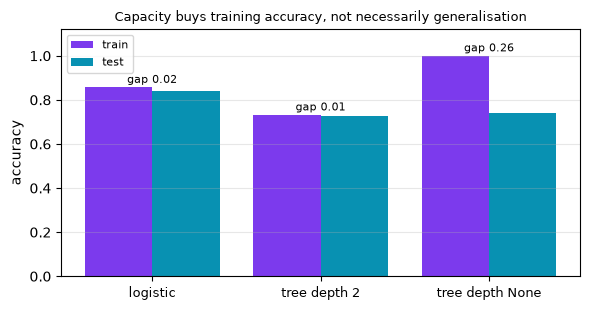

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.2))
x = np.arange(len(gap))
ax.bar(x - 0.2, gap.train_acc, width=0.4, label="train", color="#7c3aed")
ax.bar(x + 0.2, gap.test_acc, width=0.4, label="test", color="#0891b2")
for i, g in enumerate(gap.gap):
    ax.annotate(f"gap {g:.2f}", (i, max(gap.train_acc[i], gap.test_acc[i]) + 0.02),
                ha="center", fontsize=8)
ax.set_xticks(x, gap.model, fontsize=9)
ax.set_ylim(0, 1.12)
ax.set_ylabel("accuracy")
ax.set_title("Capacity buys training accuracy, not necessarily generalisation", fontsize=9)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — a chart whose purple and teal bars coincide for the shallow tree and diverge for
the deep one. The annotation is the security-relevant number.

### Step 2 — Memorisation of label noise

Flip 20 % of the training labels at random. A model with capacity will fit the flipped labels — that is
memorisation in its purest form. Test accuracy falls, and the *confidence* on flipped training points
stays high, which is exactly the signal Module 09's membership inference uses.

In [4]:
flip_rng = np.random.default_rng(SEED + 1)
y_noisy = y_train.copy()
flip_idx = flip_rng.choice(len(y_noisy), size=int(0.2 * len(y_noisy)), replace=False)
y_noisy[flip_idx] = 1 - y_noisy[flip_idx]

tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_noisy)
conf = tree.predict_proba(X_train)[:, 1]
true_conf = np.where(y_noisy == 1, conf, 1 - conf)

for label, mask in [("flipped", np.isin(np.arange(len(y_noisy)), flip_idx)),
                    ("clean", ~np.isin(np.arange(len(y_noisy)), flip_idx))]:
    print(f"{label:8} n={mask.sum():4d} mean confidence in stored label {true_conf[mask].mean():.3f}")

print(f"test accuracy after noise: {accuracy_score(y_test, tree.predict(X_test)):.3f}")

flipped  n= 168 mean confidence in stored label 1.000
clean    n= 672 mean confidence in stored label 1.000
test accuracy after noise: 0.656


**Expected output** — mean confidence near 1.0 for *both* flipped and clean training rows, and a test
accuracy noticeably lower than the 0.83-ish of the clean tree. The model believes its mistakes, which
is why "the model is confident" is not evidence that the model is right.

### Step 3 — Covariate shift without retraining

Now pretend the world moved: a new analyser reports the first assay with the opposite sign, so one feature
arrives negated. The model is unchanged; only the encoding of the inputs is.

In [5]:
X_shifted, y_shifted = make_data(seed=SEED + 2)
X_shifted[:, 0] = -X_shifted[:, 0]      # the new analyser reports the assay with the opposite sign
logit = LogisticRegression(max_iter=1000).fit(X_train, y_train)

acc_in = accuracy_score(y_test, logit.predict(X_test))
acc_out = accuracy_score(y_shifted, logit.predict(X_shifted))
print(f"in-distribution        {acc_in:.3f}")
print(f"after the sign change  {acc_out:.3f}")
print(f"drop                   {acc_in - acc_out:.3f}")

# No exception, no warning, similar latency - and the positive rate looks unremarkable.
pred_out = logit.predict(X_shifted)
print("positive rate before", round(float(logit.predict(X_test).mean()), 3),
      "| after", round(float(pred_out.mean()), 3))

in-distribution        0.839
after the sign change  0.520
drop                   0.319
positive rate before 0.489 | after 0.482


**Expected output** — accuracy falls from about 0.84 to about 0.52 (roughly a 0.3 drop) with no exception
raised anywhere, while the positive rate stays close to 0.5 on both sides. That last detail is the trap: an
aggregate dashboard on the positive rate looks healthy while a third of the decisions are now wrong.

### Step 4 — Per-slice error, not just overall error

A model can be accurate overall and wrong for a subgroup. Here "subgroup" is defined by a feature that
happens to matter — the kind of slice a fairness review asks for.

In [6]:
slices = pd.qcut(X_test[:, 0], 3, labels=["low x1", "mid x1", "high x1"])
frame = pd.DataFrame({"slice": slices, "y": y_test, "pred": logit.predict(X_test)})
per_slice = frame.groupby("slice", observed=True).apply(
    lambda g: pd.Series(
        {"n": len(g), "accuracy": round(float((g.y == g.pred).mean()), 3)}
    )
)
per_slice

,n,accuracy
slice,,
low x1,120.0,0.892
mid x1,120.0,0.783
high x1,120.0,0.842


**Expected output** — three rows whose accuracies differ. The worst slice is the one to report; an
average over all three would hide it, which is the argument for per-slice reporting in Module 19.

## Exercises

1. **Find the capacity threshold.** Sweep `max_depth` from 1 to 12, plot the gap, and identify where
   memorisation starts.
2. **Change the noise rate.** Repeat Step 2 at 10 % and 40 % label noise. At which rate does the model
   stop fitting the flips, and why?
3. **Detect the shift.** Compute the mean of each feature in `X_test` and `X_shifted` and design a
   simple rule that would fire an alert (Module 18 formalises this as PSI).
4. **Break a slice.** Split by `x2` instead of `x1` and explain why slice choice changes the story.

## Reflection questions

1. A model with train accuracy 1.0 arrives for review. What three questions do you ask first?
2. Why is covariate shift harder to notice than a crash, and what would you instrument to notice it?
3. Memorisation is a privacy problem *and* a robustness problem. Explain both with reference to the
   numbers produced above.

## References

1. Sculley, D. et al., "Hidden Technical Debt in Machine Learning Systems", NeurIPS 2015.
2. Zhang, C. et al., "Understanding Deep Learning Requires Rethinking Generalization", ICLR 2017.
3. Gama, J. et al., "A Survey on Concept Drift Adaptation", ACM Computing Surveys, 2014.
4. Carlini, N. et al., "The Secret Sharer", USENIX Security 2019.